# Ciencia a tu tesis: recomendación de artículos científicos

Este cuaderno explica, sección por sección, cómo funciona el recomendador: de dónde vienen los datos, qué características del catálogo guiaron el diseño, cómo se representan los artículos y la consulta del estudiante, cómo se ordenan los resultados y qué mostró la evaluación. El sistema ordena por afinidad temática; no mide la calidad científica de los artículos.

Para ejecutarlo hacen falta el catálogo y los índices (ver la sección 12).

## 1. Fuente y objetivo

El catálogo combina dos fuentes de metadatos abiertas. **OpenAlex** (licencia CC0) aporta una muestra estratificada de sus 26 campos académicos. **SciELO ArticleMeta** aporta una muestra de sus 19 colecciones nacionales y temáticas, con más presencia latinoamericana y en español; los términos de reutilización de cada artículo dependen de su revista. Se usan títulos, resúmenes, palabras clave y metadatos, no el texto completo.

La tarea: dada la descripción de un proyecto de grado, devolver 10 artículos temáticamente pertinentes como punto de partida de la revisión bibliográfica.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from sisreco.settings import CATALOG, DATA_MANIFEST
if not CATALOG.exists(): print('Falta el catálogo: ejecuta python scripts/download_data.py desde la raíz del proyecto.')

## 2. El catálogo

El catálogo final reúne artículos publicados entre 2016 y 2025. El manifiesto registra la fecha de extracción, los filtros, el informe de limpieza y el hash del archivo, para identificar exactamente qué datos se usaron.

In [2]:
import json
import pandas as pd
catalog = pd.read_parquet(CATALOG)
manifest = json.loads(DATA_MANIFEST.read_text(encoding='utf-8'))
print(f'{len(catalog):,} artículos · extracción {manifest["retrieved_at_utc"][:10]} · SHA-256 {manifest["catalog_sha256"][:16]}…')
display(pd.crosstab(catalog['source_database'], catalog['language'], margins=True))

108,252 artículos · extracción 2026-10-17 · SHA-256 b3aa48309c2cfa74…


language,en,es,All
source_database,,,
OpenAlex,101713,3020,104733
SciELO,823,2696,3519
All,102536,5716,108252


## 3. Análisis exploratorio del catálogo

Esta sección describe el catálogo antes de la limpieza de textos. Cada hallazgo motiva una decisión de diseño que se indica debajo de su tabla o figura.

In [3]:
import re
import matplotlib.pyplot as plt
from sisreco.catalog import load_catalog_before_text_cleaning
eda = load_catalog_before_text_cleaning()
print(f'{len(eda):,} artículos antes de la limpieza de textos')

110,474 artículos antes de la limpieza de textos


### 3.1 Distribución por año, fuente, idioma y campo

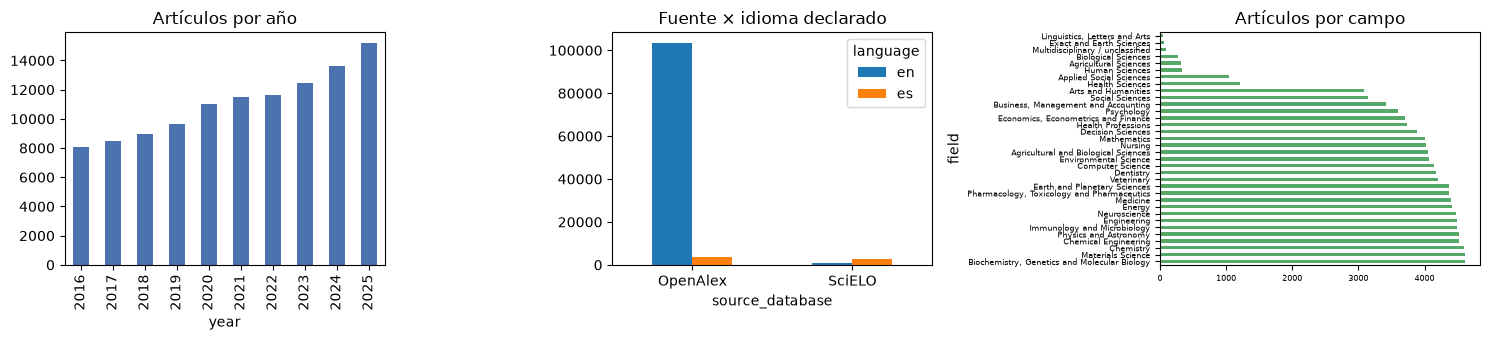

language,en,es,All
source_database,,,
OpenAlex,103220,3725,106945
SciELO,820,2709,3529
All,104040,6434,110474


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
eda['year'].value_counts().sort_index().plot.bar(ax=axes[0], title='Artículos por año', color='#4C72B0')
pd.crosstab(eda['source_database'], eda['language']).plot.bar(ax=axes[1], title='Fuente × idioma declarado', rot=0)
eda['field'].value_counts().plot.barh(ax=axes[2], title='Artículos por campo', fontsize=6, color='#55A868')
plt.tight_layout(); plt.show()
display(pd.crosstab(eda['source_database'], eda['language'], margins=True))

In [5]:
field_language = pd.crosstab(eda['field'], eda['language'])
field_language['% español'] = (100 * field_language['es'] / field_language.sum(axis=1)).round(1)
field_language['fuente'] = eda.groupby('field')['source_database'].agg(lambda s: s.mode().iloc[0])
display(field_language.sort_values('% español'))
low_spanish = field_language[field_language['% español'] < 1].index.tolist()
print('Campos con menos del 1 % de artículos en español:', low_spanish)

language,en,es,% español,fuente
field,,,,
Physics and Astronomy,4504,15,0.3,OpenAlex
Materials Science,4581,26,0.6,OpenAlex
Chemistry,4571,33,0.7,OpenAlex
Chemical Engineering,4491,37,0.8,OpenAlex
"Biochemistry, Genetics and Molecular Biology",4549,59,1.3,OpenAlex
Neuroscience,4401,72,1.6,OpenAlex
"Pharmacology, Toxicology and Pharmaceutics",4298,71,1.6,OpenAlex
Energy,4334,80,1.8,OpenAlex
Immunology and Microbiology,4391,102,2.3,OpenAlex


Campos con menos del 1 % de artículos en español: ['Chemical Engineering', 'Chemistry', 'Materials Science', 'Physics and Astronomy']


**Interpretación.** El catálogo crece hacia los años recientes y está dominado por OpenAlex y por el inglés; casi todo el español de SciELO se concentra en sus nueve categorías propias, que no equivalen a los 26 campos de OpenAlex. En física, materiales y química hay menos del 1 % de artículos en español, de modo que una consulta en español en esas áreas casi siempre recibirá literatura en inglés. Por eso las consultas de evaluación se estratifican por idioma y la exposición se mide por idioma y fuente.

### 3.2 Longitud en tokens del texto indexado

/home/juancamuba/university/recommender-systems/SistemaRecomendador/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


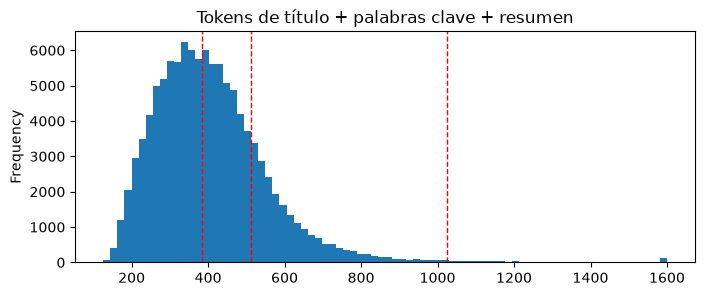

,count,mean,std,min,50%,90%,95%,99%,max
tokens,110474.0,409.0,158.0,126.0,388.0,585.0,669.0,938.0,3364.0


> 512 tokens: 19.5% · > 1.024 tokens: 0.67%


fracción > 512
source_database language                
OpenAlex        en                 0.202
                es                 0.116
SciELO          en                 0.113
                es                 0.069

In [6]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained('BAAI/bge-m3')
keywords_text = eda['keywords'].map(lambda values: ', '.join(values) if values is not None else '')
indexed_text = (eda['title'] + '. ' + keywords_text + '. ' + eda['abstract']).tolist()
token_lengths = pd.Series([len(ids) for ids in tokenizer(indexed_text, truncation=False)['input_ids']], index=eda.index)
token_lengths.clip(upper=1600).plot.hist(bins=80, figsize=(8, 3), title='Tokens de título + palabras clave + resumen')
for limit in (384, 512, 1024): plt.axvline(limit, color='red', linestyle='--', linewidth=1)
plt.show()
display(token_lengths.describe(percentiles=[.5, .9, .95, .99]).round(0).to_frame('tokens').T)
print(f'> 512 tokens: {(token_lengths > 512).mean():.1%} · > 1.024 tokens: {(token_lengths > 1024).mean():.2%}')
display((token_lengths > 512).groupby([eda['source_database'], eda['language']]).mean().round(3).to_frame('fracción > 512'))

**Interpretación.** Una quinta parte de los textos supera los 512 tokens y el percentil 99 está por debajo de 1.024, así que un límite de 1.024 tokens procesa completo el 99 % del catálogo. Los textos largos se concentran en OpenAlex y en inglés; con un límite de 512, el recorte afectaría más a esos artículos que a los de SciELO.

### 3.3 Calidad de los resúmenes

In [7]:
from sisreco.catalog import abstract_quality_flags
flags = abstract_quality_flags(eda)
display(flags.sum().to_frame('artículos'))
display(flags.groupby(eda['source_database']).sum())
for column in ('copyright', 'front_matter', 'shared_abstract'):
    example = eda.loc[flags[column], 'abstract']
    if not example.empty: print(f'{column}: …{example.iloc[0][-160:]}')

,artículos
empty_or_short,0
label_prefix,15197
copyright,756
mojibake,35
front_matter,21
shared_abstract,73


,empty_or_short,label_prefix,copyright,mojibake,front_matter,shared_abstract
source_database,,,,,,
OpenAlex,0,12327,749,30,21,73
SciELO,0,2870,7,5,0,0


copyright: …which may be most apparent among those retiring from jobs with low complexity of work with people. (PsycInfo Database Record (c) 2021 APA, all rights reserved).
front_matter: …8 April 2017 Issue Published: 16 May 2017 Copyright & PermissionsCopyright © 2017 by American College of Physicians. All Rights Reserved.PDF downloadLoading ...
shared_abstract: …ical component. It aims to bridge the significant gap between research and practice by promoting the publication of original, novel, industry-relevant research.


**Interpretación.** Ningún resumen está vacío o es más corto que 80 palabras, porque la descarga ya los excluye. Los problemas son otros: rótulos al inicio ("Abstract", "Resumen"), avisos de derechos de autor al final, caracteres mal codificados, portadillas editoriales en lugar del resumen y resúmenes repetidos que describen la revista y no el artículo. Los rótulos aparecen en el 81 % de los resúmenes de SciELO; los avisos, las portadillas y los resúmenes compartidos provienen casi solo de OpenAlex. Los rótulos y los avisos se eliminan del texto, y se excluyen los artículos cuyo resumen no describe el artículo.

### 3.4 Coherencia del idioma declarado

In [8]:
from langdetect import DetectorFactory, detect
DetectorFactory.seed = 42
language_sample = eda.sample(2000, random_state=42)
detected = language_sample['abstract'].map(detect)
display(pd.crosstab(language_sample['language'], detected, rownames=['declarado'], colnames=['detectado en el resumen']))
mismatch = language_sample['language'].ne(detected)
print(f'Desacuerdo: {mismatch.mean():.1%} de la muestra')
display(mismatch.groupby([language_sample['source_database'], language_sample['language']]).mean().round(3).to_frame('desacuerdo'))
declared_spanish = eda[eda['language'].eq('es')]
detected_spanish = declared_spanish['abstract'].map(detect)
print(f'Declarados en español en todo el catálogo: {len(declared_spanish):,}; resumen detectado en otro idioma: {detected_spanish.ne("es").sum():,} ({detected_spanish.ne("es").mean():.1%})')
display(detected_spanish[detected_spanish.ne('es')].groupby(declared_spanish['source_database']).value_counts().to_frame('artículos'))

detectado en el resumen,de,en,es,fi,he,hr,id,it,ja,ko,pl,pt,ru,th,tr,uk
declarado,,,,,,,,,,,,,,,,
en,1,1844,3,1,1,1,17,0,1,11,3,3,2,1,1,3
es,0,12,94,0,0,0,0,1,0,0,0,0,0,0,0,0


Desacuerdo: 3.1% de la muestra


desacuerdo
source_database language            
OpenAlex        en             0.026
                es             0.228
SciELO          en             0.000
                es             0.000

Declarados en español en todo el catálogo: 6,434; resumen detectado en otro idioma: 795 (12.4%)


artículos
source_database abstract           
OpenAlex        en              751
                pt               26
                fr                3
                ca                2
                de                2
                it                1
SciELO          en                6
                pt                4

**Interpretación.** El idioma declarado de OpenAlex corresponde con frecuencia al título y no al resumen: muchos artículos con título en español tienen el resumen en inglés, y algunos declarados en inglés tienen el resumen en portugués, indonesio, coreano o ruso. Como el filtro de idioma y las métricas por idioma dependen de este campo, la preparación asigna el idioma detectado en el resumen y excluye los resúmenes que no están en español ni en inglés.

### 3.5 Términos ambiguos por campo

In [9]:
ambiguous_terms = {
    'agente / agent': r'\bagents?\b|\bagentes?\b',
    'arquitectura / architecture': r'\barchitectur\w*|\barquitectur\w*',
    'modelo / model': r'\bmodels?\b|\bmodel(?:o|os)\b',
    'red / network': r'\bnetworks?\b|\bred(?:es)?\b',
}
lowered = (eda['title'] + ' ' + eda['abstract']).str.lower()
term_share = pd.DataFrame({term: lowered.str.contains(pattern, regex=True).groupby(eda['field']).mean() * 100
                           for term, pattern in ambiguous_terms.items()}).round(1)
for term in ambiguous_terms:
    print(term, '→', ', '.join(f'{field} ({share} %)' for field, share in term_share[term].nlargest(4).items()))

agente / agent → Pharmacology, Toxicology and Pharmaceutics (9.5 %), Immunology and Microbiology (8.9 %), Chemistry (7.1 %), Materials Science (6.6 %)
arquitectura / architecture → Computer Science (8.4 %), Exact and Earth Sciences (4.7 %), Engineering (4.1 %), Arts and Humanities (2.8 %)
modelo / model → Decision Sciences (38.3 %), Computer Science (35.0 %), Physics and Astronomy (32.5 %), Earth and Planetary Sciences (32.0 %)
red / network → Computer Science (24.9 %), Neuroscience (13.1 %), Engineering (11.0 %), Decision Sciences (9.3 %)


**Interpretación.** "Agente" aparece sobre todo en farmacología, inmunología, química y materiales (agentes químicos o infecciosos), no en computación; "arquitectura" se reparte entre computación, ingeniería, ciencias exactas y de la Tierra y humanidades; "red" y "modelo" atraviesan casi todos los campos. Una consulta sobre agentes de inteligencia artificial o arquitectura de software compite con esos sentidos. Estos términos se usan para diseñar perfiles de evaluación difíciles y para revisar los errores.

## 4. Preparación del texto

Los hallazgos de la sección 3 se resuelven en `sisreco.catalog.prepare_texts`, que se aplica al reconstruir el catálogo:

- normaliza Unicode y espacios y repara el texto UTF-8 leído como Latin-1;
- quita el rótulo inicial ("Abstract", "Resumen") y el aviso editorial final;
- excluye las portadillas y los resúmenes compartidos por varios artículos, porque no describen el artículo;
- asigna como idioma el detectado en el resumen y excluye los resúmenes que no están en español ni en inglés.

El texto que se indexa para cada artículo es `título. palabras clave. topic. resumen`. El campo queda solo como filtro.

In [10]:
report = manifest['text_cleaning']
print(f"Entraron {report['records_in']:,} artículos y quedaron {report['records_out']:,}.")
print(f"Texto modificado: {report['modified_text']:,} · idioma corregido: {report['relabelled_language']:,}")
display(pd.Series(report['excluded'], name='excluidos').to_frame())
display(pd.Series(report['excluded_by_source_language'], name='excluidos').to_frame())
from sisreco.engine import article_text
print(article_text(catalog.iloc[0])[:400], '…')

Entraron 110,474 artículos y quedaron 108,252.
Texto modificado: 16,462 · idioma corregido: 846


,excluidos
language_not_en_es,2080
shared_abstract,73
short_after_cleaning,48
front_matter,21


,excluidos
OpenAlex|en|front_matter,21
OpenAlex|en|language_not_en_es,2042
OpenAlex|en|shared_abstract,73
OpenAlex|en|short_after_cleaning,42
OpenAlex|es|language_not_en_es,34
SciELO|es|language_not_en_es,4
SciELO|es|short_after_cleaning,6


Water for Food: Legal and Environmental Dimensions of Agricultural Water Trade in South Asia. transboundary water resources, agricultural water use, irrigation, food security, water conflicts, dispute resolution mechanisms, environmental safeguards, regional water cooperation, climate change adaptation, water scarcity, South Asia, India, Pakistan, Nepal, Bangladesh. Transboundary Water Resource Ma …


**Interpretación.** La limpieza modifica sobre todo rótulos y avisos, y casi todas las exclusiones se deben a resúmenes en otros idiomas. Esas exclusiones pesan más en ciencias sociales, administración y humanidades (alrededor del 7 % de cada campo) que en el resto (mediana del 1,3 %), lo que es un sesgo de selección que se discute en la sección 11.

## 5. Representación y modelo

- **Recuperación densa.** `BAAI/bge-m3` convierte cada artículo en un vector de 1.024 dimensiones normalizado. Lee hasta 1.024 tokens, lo que cubre completo el 99 % del texto indexado según la sección 3.2. La consulta del estudiante (descripción + `". Palabras clave: "` + palabras clave) se codifica con el mismo modelo, y se comparan por similitud coseno con búsqueda exacta.
- **Reordenamiento.** Los 100 artículos más cercanos pasan a `BAAI/bge-reranker-v2-m3`, un modelo que lee la consulta y cada artículo juntos y devuelve un puntaje de pertinencia. Se muestran los 10 primeros, sin umbral: los puntajes no están calibrados entre consultas, y un corte fijo dejaba listas incompletas.
- **Referencia.** TF-IDF de unigramas y bigramas sobre los artículos en inglés.

In [11]:
from sisreco.engine import load_reranker, load_retriever, load_vectors, recommend, recommend_similar, build_query
from sisreco.settings import RERANKER, RETRIEVER
vectors = load_vectors(catalog, RETRIEVER)
retriever = load_retriever(RETRIEVER)
reranker = load_reranker(RERANKER)
index_manifest = json.loads(RETRIEVER.vectors_path.with_suffix('.json').read_text(encoding='utf-8'))
print('Vectores:', vectors.shape, '· revisión del modelo:', index_manifest['revision'][:12])
print(f"Textos que superan {RETRIEVER.max_seq_length} tokens: {index_manifest['truncated_fraction']:.2%}")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   1%|▏         | 5/391 [00:00<01:09,  5.58it/s]

Loading weights:  71%|███████   | 277/391 [00:01<00:00, 375.76it/s]

Loading weights: 100%|██████████| 391/391 [00:01<00:00, 342.81it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

...

Loading weights:  56%|█████▌    | 220/393 [00:00<00:00, 395.34it/s]

Loading weights:  74%|███████▎  | 289/393 [00:00<00:00, 433.58it/s]

Loading weights:  90%|████████▉ | 352/393 [00:00<00:00, 480.96it/s]

Loading weights: 100%|██████████| 393/393 [00:01<00:00, 383.85it/s]

Vectores: (108252, 1024) · revisión del modelo: 5617a9f61b02
Textos que superan 1024 tokens: 0.63%


## 6. Ejemplo: un perfil de estudiante

Una estudiante quiere estudiar el pronóstico de energía solar y eólica con aprendizaje automático. Escribe su descripción en español y agrega dos palabras clave.

In [12]:
query = build_query('Quiero investigar el uso de aprendizaje automático para predecir la generación de energía solar y eólica y mejorar la operación de redes eléctricas.',
                    'pronóstico, energías renovables')
results = recommend(catalog, query, top_k=5, vectors=vectors, retriever=retriever, reranker=reranker)
display(results[['title', 'year', 'language', 'field', 'score', 'evidence']])

,title,year,language,field,score,evidence
0,Is artificial intelligence an impediment or an...,2025,en,Energy,0.862305,"The results inform policy-makers, investors, a..."
1,Comparative Analysis of Machine Learning Model...,2021,en,Computer Science,0.444336,The purpose of this work is to address these t...
2,Applications of machine learning and artificia...,2025,en,Computer Science,0.368164,The integration of advanced machine learning (...
3,Optimal Configuration Planning of Multi-Energy...,2023,en,Energy,0.321533,"First, the prediction of weather and loading d..."
4,Uso de las Energías Alternativas en la Contrib...,2025,es,Energy,0.312500,Este estudio tiene como propósito interpretar ...


**Interpretación.** El sistema recupera artículos en inglés y en español para una consulta en español, porque bge-m3 representa ambos idiomas en el mismo espacio. La lista mezcla aciertos directos, como la comparación de modelos de aprendizaje automático, con artículos vecinos: el primero trata el efecto de la inteligencia artificial sobre la inversión en energías renovables, no el pronóstico. Es el patrón que encontró la verificación humana: el reordenador a veces coloca arriba un artículo que comparte los conceptos, pero no el objetivo. La columna `evidence` muestra la oración del resumen más cercana a la consulta, para que la estudiante juzgue cada resultado.

## 7. Referencia TF-IDF

TF-IDF solo compara palabras exactas, así que se usa con consultas en inglés. Sirve para ver qué aporta la representación semántica frente a la coincidencia de términos.

In [13]:
query_en = 'I want to study machine learning for solar and wind energy generation forecasting and improved electric grid operation.'
display(recommend(catalog, query_en, engine='tfidf', top_k=5)[['title', 'year', 'field', 'score']])

,title,year,field,score
0,Techno‐economic evaluation of standalone hybri...,2017,Energy,0.305503
1,Solar Wind Hybrid Energy System,2019,Energy,0.294203
2,Grid Integration of Renewable Energy for Relia...,2025,Energy,0.284360
3,Grid Integration Challenges of Wind Energy: A ...,2020,Energy,0.279607
4,Maximising the contribution of renewables in a...,2020,Energy,0.279277


## 8. Artículos similares

Desde cualquier resultado, el estudiante puede pedir artículos parecidos. El sistema reutiliza el vector ya indexado del artículo elegido, sin volver a ejecutar los modelos, y excluye el artículo de referencia y sus duplicados por DOI o título.

In [14]:
seed = results.iloc[0]
print('Referencia:', seed['title'])
display(recommend_similar(catalog, seed['id'], top_k=5, vectors=vectors)[['title', 'year', 'language', 'score']])

Referencia: Is artificial intelligence an impediment or an impetus to renewable energy investment? Evidence from China


,title,year,language,score
0,The Impact of Artificial Intelligence on Energ...,2025,en,0.791028
1,Can artificial intelligence technology innovat...,2024,en,0.783228
2,Do Artificial Intelligence Applications Affect...,2022,en,0.769842
3,Can Artificial Intelligence Improve the Energy...,2022,en,0.744337
4,The role of renewable energy in mitigating car...,2025,en,0.741332


## 9. Evaluación

Se compararon siete configuraciones, cambiando una cosa a la vez: **A** (referencia: e5-small + reordenador mMARCO), **B** (recuperador bge-m3 sin reordenador), **C** (B + reordenador bge-reranker-v2-m3; la configuración final), **D** (C leyendo 1.024 tokens en el reordenador) **E** (C con la lista corta fusionada con un índice léxico bilingüe), y **F** y **G** (C diversificada con MMR, λ = 0,7 y 0,5; son las opciones "equilibrados" y "más variados" de la aplicación). Las métricas automáticas usan 200 consultas de ítem conocido redactadas como las escribiría un estudiante: la mitad en español y la mitad en inglés, sin filtros. La verificación humana usa 10 perfiles bilingües calificados a ciegas.

In [15]:
from sisreco.settings import ARTIFACTS_DIR
display(pd.read_csv(ARTIFACTS_DIR / 'evaluation_metrics.csv').round(3))
comparison = pd.read_csv(ARTIFACTS_DIR / 'evaluation_comparison.csv')
display(comparison[comparison['metric'].eq('mrr@10')].round(4))

,config,queries,mrr_at_10,recall_at_10,mrr_gap_es_en,topic_precision_at_10,ild_at_10,share_spanish_top10,share_scielo_top10
0,A,200,0.640,0.810,0.048,0.306,0.451,0.135,0.066
1,B,200,0.730,0.880,0.050,0.410,0.387,0.097,0.051
2,C,200,0.900,0.970,0.063,0.490,0.390,0.145,0.069
3,D,200,0.886,0.970,0.068,0.483,0.390,0.142,0.068
4,E,200,0.885,0.950,0.070,0.480,0.398,0.182,0.092
5,F,200,0.899,0.970,0.065,0.454,0.411,0.156,0.078
6,G,200,0.899,0.965,0.067,0.419,0.427,0.159,0.081


,config_a,config_b,metric,score_a,score_b,difference,p_value
0,A,B,mrr@10,0.6396,0.7303,0.0907,0.0070
2,A,C,mrr@10,0.6396,0.8999,0.2603,0.0000
4,A,D,mrr@10,0.6396,0.8862,0.2467,0.0000
6,A,E,mrr@10,0.6396,0.8849,0.2453,0.0000
8,A,F,mrr@10,0.6396,0.8993,0.2597,0.0000
10,A,G,mrr@10,0.6396,0.8985,0.2590,0.0000
12,B,C,mrr@10,0.7303,0.8999,0.1695,0.0000
14,B,D,mrr@10,0.7303,0.8862,0.1559,0.0000
16,B,E,mrr@10,0.7303,0.8849,0.1545,0.0000
18,B,F,mrr@10,0.7303,0.8993,0.1690,0.0000


In [16]:
breakdown = pd.read_csv(ARTIFACTS_DIR / 'evaluation_breakdown.csv')
display(breakdown[breakdown['config'].isin(['A', 'C'])].pivot_table(index=['dimension', 'group'], columns='config', values='mrr_at_10').round(3))
display(pd.read_csv(ARTIFACTS_DIR / 'evaluation_exposure.csv').round(3))

config                                        A      C
dimension                       group                 
article_language                en        0.636  0.886
                                es        0.652  0.956
query_language                  en        0.616  0.931
                                es        0.664  0.868
query_language×article_language en→en     0.588  0.936
                                en→es     0.725  0.912
                                es→en     0.684  0.835
                                es→es     0.580  1.000
source_database                 OpenAlex  0.640  0.889
                                SciELO    0.640  0.979

,config,query_language,share_spanish_others,share_scielo_others,catalog_share_spanish,catalog_share_scielo,ratio_spanish,ratio_scielo
0,A,en,0.096,0.031,0.053,0.033,1.824,0.967
1,A,es,0.163,0.092,0.053,0.033,3.079,2.820
2,B,en,0.054,0.027,0.053,0.033,1.016,0.844
3,B,es,0.121,0.060,0.053,0.033,2.287,1.832
4,C,en,0.055,0.025,0.053,0.033,1.048,0.783
5,C,es,0.222,0.102,0.053,0.033,4.196,3.138
6,D,en,0.051,0.024,0.053,0.033,0.964,0.749
7,D,es,0.219,0.100,0.053,0.033,4.156,3.073
8,E,en,0.035,0.021,0.053,0.033,0.667,0.646
9,E,es,0.326,0.155,0.053,0.033,6.172,4.775


In [17]:
human = ARTIFACTS_DIR / 'human_metrics.csv'
if human.exists():
    display(pd.read_csv(human).round(3))
    display(pd.read_csv(ARTIFACTS_DIR / 'human_comparison.csv').round(4))
else:
    print('Sin juicios humanos: genera la hoja con scripts/prepare_evaluation.py y califícala.')

,config,precision_at_5,precision_at_5_grade2,ndcg_at_5,query_language
0,A,0.81,0.39,0.673,todos
1,C,0.82,0.39,0.629,todos
2,A,0.80,0.42,0.688,en
3,A,0.82,0.36,0.659,es
4,C,0.86,0.42,0.681,en
5,C,0.78,0.36,0.577,es


,metric,reference,chosen,queries,difference,chosen_better,ties,chosen_worse,p_value
0,precision_at_5,A,C,20,0.0100,6,9,5,0.9447
1,precision_at_5_grade2,A,C,20,0.0000,6,7,7,0.9521
2,ndcg_at_5,A,C,20,-0.0441,9,2,9,0.2826


**Interpretación.** C encuentra el artículo de origen en el top 10 en el 97 % de las consultas y supera a A en MRR@10 por +0,26 (p < 0,00001), con una brecha entre español e inglés de 0,063. D y E no la superan; F y G mantienen el MRR y hacen las listas más variadas (ILD de 0,390 a 0,411 y 0,427) a cambio de menos coherencia temática. En la verificación humana, C alcanza P@5 = 0,82, pero no se distingue de A: las dos configuraciones devuelven artículos útiles para temas amplios, y C prioriza artículos en el idioma de la consulta. La exposición muestra ese efecto: con consultas en inglés, C refleja la proporción de español del catálogo; con consultas en español, la multiplica por 4,2.

## 10. Arranque en frío

- **Estudiante nuevo:** la descripción del proyecto y sus palabras clave reemplazan el historial; el sistema recomienda desde la primera consulta, sin valoraciones previas.
- **Artículo nuevo:** basta con limpiar su texto y calcular su vector con bge-m3; no necesita interacciones de otros usuarios para poder recomendarse.

## 11. Sesgos y limitaciones

- **Preexistentes:** el catálogo es 94,7 % inglés y 96,7 % OpenAlex; en cinco campos el español no llega al 1 %.
- **De selección:** la limpieza excluye más artículos de ciencias sociales, administración y humanidades, cuyos resúmenes suelen estar en otros idiomas.
- **Técnicos:** el reordenador prefiere el idioma de la consulta; las categorías de SciELO no equivalen a los campos de OpenAlex; los topics de OpenAlex se asignan automáticamente.
- **Emergentes:** las listas de C son más homogéneas que las de A (ILD 0,390 frente a 0,451), lo que puede concentrar las lecturas en los mismos subtemas.

El informe (`docs/informe_proyecto.md`) propone una mitigación para cada sesgo.

## 12. Ejecutar

~~~bash
python -m pip install -r requirements-lock.txt
python scripts/download_data.py
python scripts/build_index.py
streamlit run app.py
~~~

El README describe cómo reproducir la evaluación.